<a href="https://colab.research.google.com/github/Mufliha-Hafsyah/PCVK_Ganjil_2026/blob/main/Week7_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **LAPORAN PRAKTIKUM <br> Pengolahan Citra dan Visi Komputer (PCVK)**

**Nama** : Mufliha Hafsyah Shahieza <br>
**NIM** : 244107020147 <br>
**Kelas** : TI-3G

---

## **MODUL 7 – SEGMENTASI CITRA DENGAN THRESHOLDING**

<hr>

### **D. TUGAS PRAKTIKUM**
### **D1. Tugas Individu**

1. **Akses file yang terdapat pada drive dan import beberapa library yang dibutuhkan**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


2. **Import beberapa library berikut yang akan digunakan selama uji coba praktikum
minggu ke-7 berikut.**

In [2]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

3. **Buat Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV), dengan
threshold= 200, secara manual sehingga menghasilkan tampilan seperti berikut:**

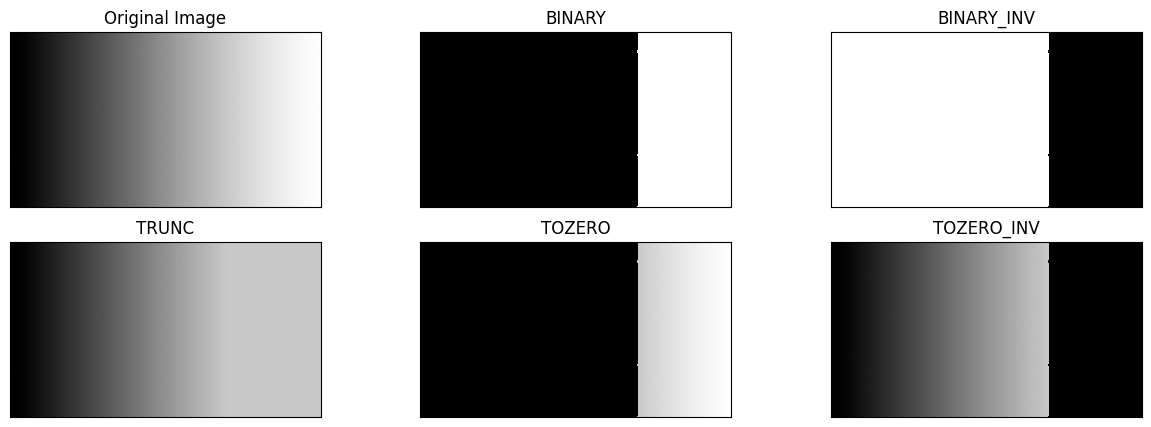

In [3]:
filename = ('/content/drive/MyDrive/PCVK2026/gradient.jpg')
img = cv.imread(filename)
thresh = 200
maxval = 255

# 1. BINARY: Jika nilai piksel > thresh maka bernilai maxval, selain itu bernilai 0
thresh1 = np.where(img > thresh, maxval, 0).astype(np.uint8)

# 2. BINARY_INV: Jika nilai piksel > thresh maka bernilai 0, selain itu bernilai maxval
thresh2 = np.where(img > thresh, 0, maxval).astype(np.uint8)

# 3. TRUNC: Jika nilai piksel > thresh maka bernilai thresh, selain itu tetap nilai asli
thresh3 = np.where(img > thresh, thresh, img).astype(np.uint8)

# 4. TOZERO: Jika nilai piksel > thresh maka tetap nilai asli, selain itu bernilai 0
thresh4 = np.where(img > thresh, img, 0).astype(np.uint8)

# 5. TOZERO_INV: Jika nilai piksel > thresh maka bernilai 0, selain itu tetap nilai asli
thresh5 = np.where(img > thresh, 0, img).astype(np.uint8)

titles = ['Original Image','BINARY','BINARY_INV','TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize = (15,5))
for i in range(len(images)):
  plt.subplot(2,3,i+1),plt.imshow(images[i],'gray', interpolation='nearest')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

**Penjelasan:**<br>
Lima jenis global threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV) dibuat secara manual dengan `np.where` menggunakan T = 200 dan maxVal 255, sesuai tabel ketentuan. Pada BINARY dan BINARY_INV citra hanya berisi hitam dan putih, dengan batas di T = 200. TRUNC memotong semua piksel di atas 200 menjadi 200 sehingga sisi kanan tampak abu-abu terang rata, sedangkan TOZERO mempertahankan nilai asli di atas T dan TOZERO_INV mempertahankan nilai asli di bawah T, sisanya menjadi 0.

4. **Buat program Addaptive Threshold : adaptive mean dan adaptive Gaussian tanpa
menggunakan cv.threshold(), cv.adaptiveThreshold(), maupun fungsi filter siap
pakai dengan menggunakan citra Sudoku yang memiliki pencahayaan tidak merata.
Ketentuan: global threshold secara manual dengan ambang 127, ukuran jendela 11 ×
11, C=2, dan sigma=2 untuk Gaussian sehingga menghasilkan tampilan seperti
berikut:**

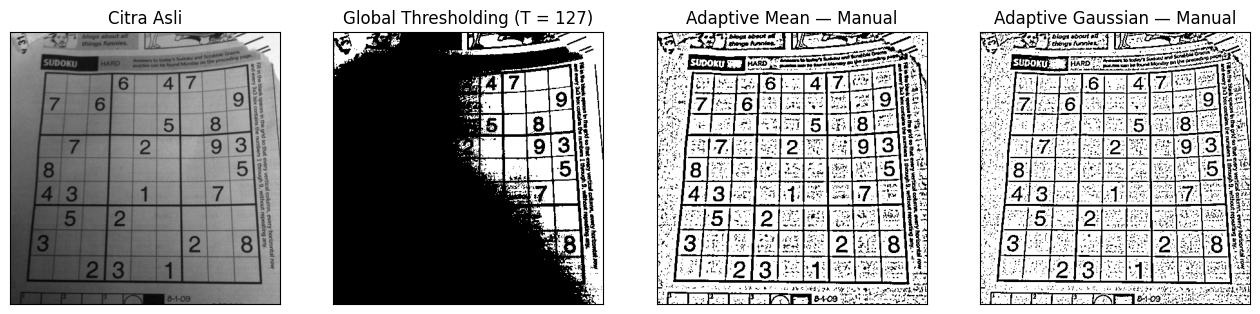

In [4]:
filename = ('/content/drive/MyDrive/PCVK2026/sudoku-original.jpg')
citra = cv.imread(filename)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

thresh = 127
blockSize = 11
C = 2
sigma = 2

# Konvolusi manual
def konvolusi(image, kernel):
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    padded = np.pad(image.astype(np.float32), ((ph, ph), (pw, pw)), mode='edge')
    H, W = image.shape
    out = np.zeros((H, W), dtype=np.float32)
    for i in range(kh):
        for j in range(kw):
            out += kernel[i, j] * padded[i:i+H, j:j+W]
    return out

# Kernel rata-rata 11x11
kernel_mean = np.ones((blockSize, blockSize), dtype=np.float32) / (blockSize * blockSize)

# Kernel Gaussian 11x11, sigma=2 (rumus Gaussian, dibuat manual)
ax = np.arange(blockSize) - blockSize // 2
g = np.exp(-(ax**2) / (2 * sigma**2))
g = g / g.sum()
kernel_gauss = np.outer(g, g).astype(np.float32)

# 1. Global threshold manual: pixel > 127 maka bernilai 255, selain itu 0
th1 = np.where(gray > thresh, 255, 0).astype(np.uint8)

# 2. Adaptive Mean: T(x,y) = rata-rata lokal - C
T_mean = konvolusi(gray, kernel_mean) - C
th2 = np.where(gray > T_mean, 255, 0).astype(np.uint8)

# 3. Adaptive Gaussian: T(x,y) = rata-rata Gaussian lokal - C
T_gauss = konvolusi(gray, kernel_gauss) - C
th3 = np.where(gray > T_gauss, 255, 0).astype(np.uint8)

titles = ['Citra Asli', 'Global Thresholding (T = 127)',
          'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
citra2 = [gray, th1, th2, th3]

plt.figure(figsize = (16,5))
for i in range(len(citra2)):
    plt.subplot(1,4,i+1),plt.imshow(citra2[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

**Penjelasan:**<br>
Adaptive Mean dan Adaptive Gaussian dibuat tanpa fungsi threshold maupun filter siap pakai. Threshold dihitung untuk setiap piksel, yaitu rata-rata nilai piksel di sekitarnya (jendela 11 × 11) dikurangi C = 2. Rata-rata ini dihitung dengan konvolusi manual memakai kernel rata-rata (Mean) dan kernel Gaussian (sigma = 2). Setelah itu, nilai setiap piksel dibandingkan dengan threshold miliknya sendiri: jika lebih besar menjadi putih (255), jika tidak menjadi hitam (0). Global threshold (T = 127) gagal pada sisi kiri sudoku yang lebih gelap karena satu nilai T tidak cocok untuk seluruh area, sehingga sisi itu menjadi hitam total. Adaptive threshold menyesuaikan ambang dengan lingkungan tiap piksel sehingga angka di area gelap tetap terbaca. Hasilnya masih berbintik pada area kertas yang homogen karena C = 2 kecil, dan Gaussian tampak sedikit lebih bersih daripada Mean.

5. **A. Buat Otsu Thresholding tanpa menggunakan Library. Tampilkan juga nilai threshold
saat anda gunakan Otsu’s, seperti terlihat pada gambar hasil berikut. (gunakan image
lena_gs_lc2.jpg untuk dibandingkan dengan hasil dengan penggunaan library.**<br>
**B. Kemudian coba dengan image KTP sendiri agar terlihat beda antara hasil otsu’s
dengan global threshold biasa)**



**A. Citra lena_gs_lc2.jpg**

/tmp/ipykernel_3689/762919682.py:19: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
/tmp/ipykernel_3689/762919682.py:20: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


93


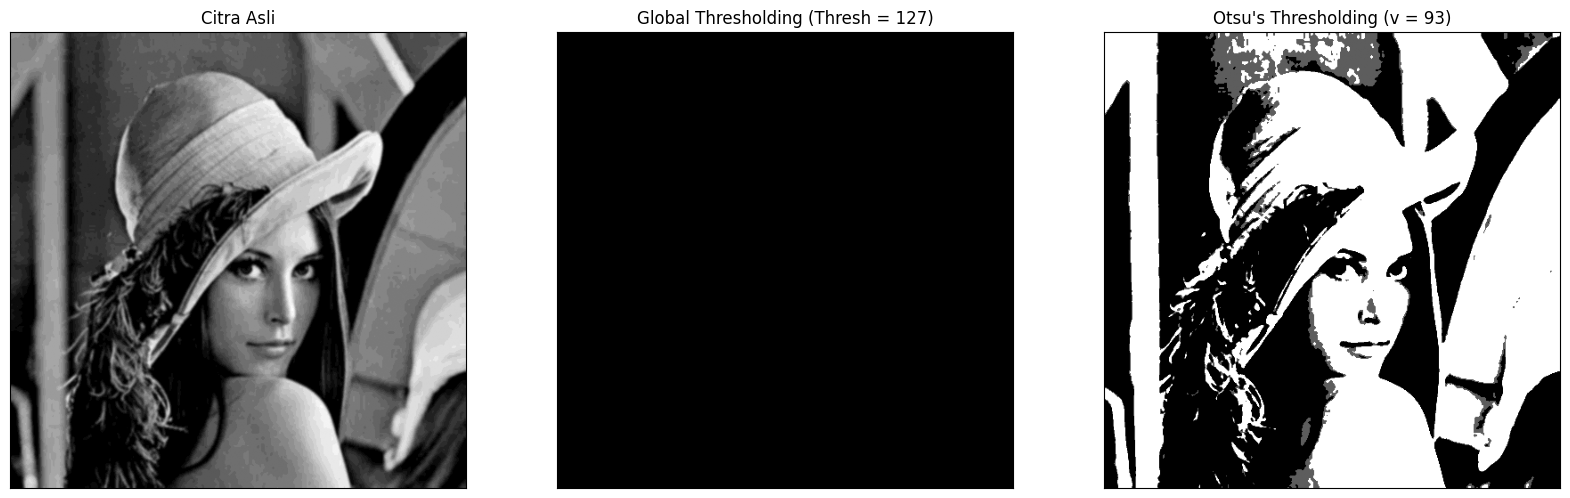

In [5]:
filename = ('/content/drive/MyDrive/PCVK2026/lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
  pixel_number = gray.shape[0] * gray.shape[1]
  mean_weight = 1.0/pixel_number
  his, bins = np.histogram(gray, np.arange(0,257))
  final_thresh = -1
  final_value = -1
  intensity_arr = np.arange(256)
  for t in bins[1:-1]:
    pcb = np.sum(his[:t])
    pcf = np.sum(his[t:])
    Wb = pcb * mean_weight
    Wf = pcf * mean_weight

    mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
    muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
    value = Wb * Wf * (mub - muf) ** 2

    if value > final_value:
      final_thresh = t
      final_value = value
  final_img = gray.copy()
  print(final_thresh)
  final_img[gray > final_thresh] = 255
  final_img[gray < final_thresh] = 0
  return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
  plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

**Pertanyaan: Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam
semuan? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas
(Thresh) supaya gambar Lena ini masih terlihat?**

/tmp/ipykernel_3689/685234006.py:2: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(),256,[0,256])


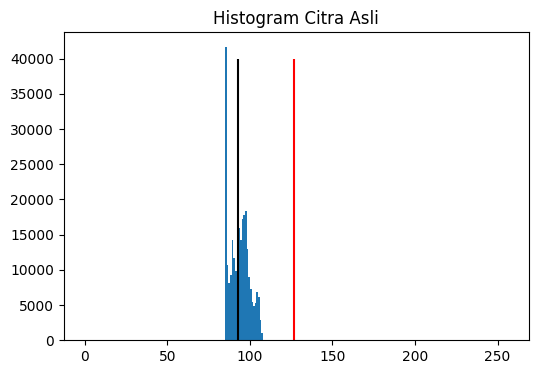

In [6]:
plt.figure(figsize = (6,4))
plt.hist(blur.ravel(),256,[0,256])
plt.vlines(thresh,0,40000,colors='red')
plt.vlines(otsu_thresh,0,40000,colors='black')
plt.title('Histogram Citra Asli')
plt.show()

**Penjelasan:**<br>
Hasil Binary Thresholding berwarna hitam semua karena citra Lena ini memiliki kontras rendah (*low contrast*). Seluruh nilai pikselnya terkumpul di rentang sempit, yaitu sekitar 85 sampai 108, sehingga nilai maksimumnya masih di bawah threshold 127. Pada histogram, garis threshold 127 (merah) berada di sebelah kanan seluruh sebaran piksel. Aturan Binary Threshold adalah jika piksel > T maka menjadi 255 (putih), dan jika piksel ≤ T maka menjadi 0 (hitam). Karena tidak ada satu pun piksel yang bernilai lebih dari 127, semua piksel menjadi 0 sehingga citra tampak hitam seluruhnya.<br>
Agar citra Lena masih terlihat, nilai T harus berada di dalam rentang sebaran histogram (sekitar 85-108) supaya ada piksel di kedua sisi threshold. Nilai yang dipilih Otsu adalah 93, sehingga T sekitar 90-95 menghasilkan citra yang masih jelas.

**B. Citra ktm_fulan.jpg**

/tmp/ipykernel_3689/762919682.py:19: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)


166


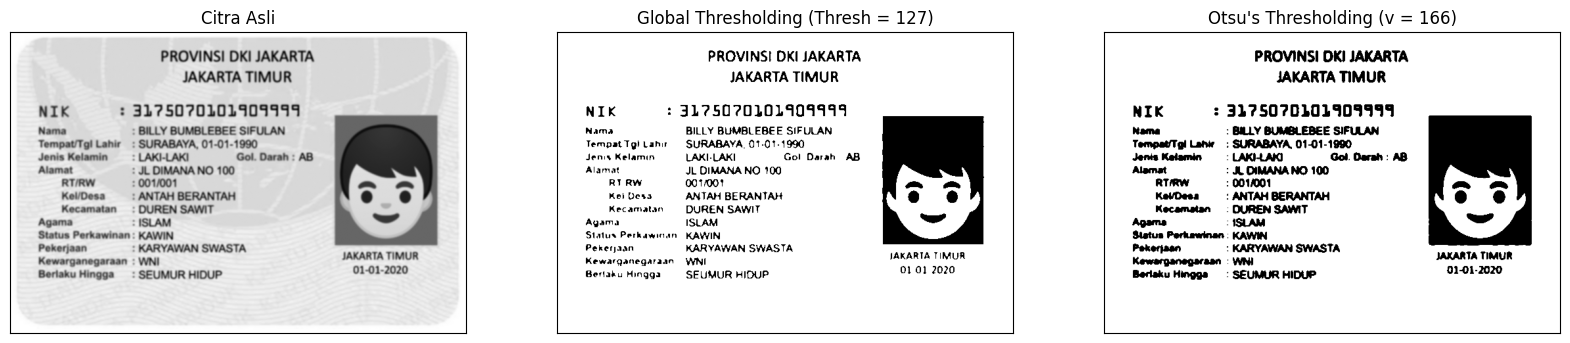

In [7]:
filename = ('/content/drive/MyDrive/PCVK2026/ktp_fulan.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

**Penjelasan:**<br>
Pada citra KTP, global thresholding dengan T = 127 sudah mampu menampilkan teks dengan cukup jelas. Namun, huruf yang kecil tampak lebih tipis dan putus-putus. Tanda baca seperti "/" dan "-" pada tanggal lahir cenderung hilang karena nilai pikselnya lebih terang dari 127, sehingga berubah menjadi maxVal atau 255 (putih). Otsu menghasilkan T = 166 yang dihitung dari histogram citra itu sendiri, sehingga goresan tipis tersebut masih terdeteksi sebagai teks dan huruf tampak lebih utuh. Perbedaannya tidak terlalu besar karena latar KTP sudah terang dan kontras dengan teks. Meski begitu, hal ini menunjukkan bahwa T = 127 adalah angka tetap yang belum tentu optimal, sedangkan Otsu menyesuaikan nilai T dengan sebaran intensitas citra.

6. **A. Lakukan Segmentasi Berbasis Region pada citra data.coins() dari skimage.**<br>
**Citra ini cocok karena memuat objek yang jelas (koin), latar yang cukup homogen,
dan beberapa koin yang saling bersentuhan. Ketentuan:<br>
• Tentukan 3 seed: satu di dalam koin, satu di latar, dan satu tepat di tepi koin.<br>
• Jalankan dengan T = 5, 20, dan 60.<br>
• Tampilkan hasilnya dalam grid 3×3 (seed × T)**

Dalam koin (36, 43) | intensitas: 159
Latar (5, 5) | intensitas: 133
Tepi koin (36, 38) | intensitas: 123


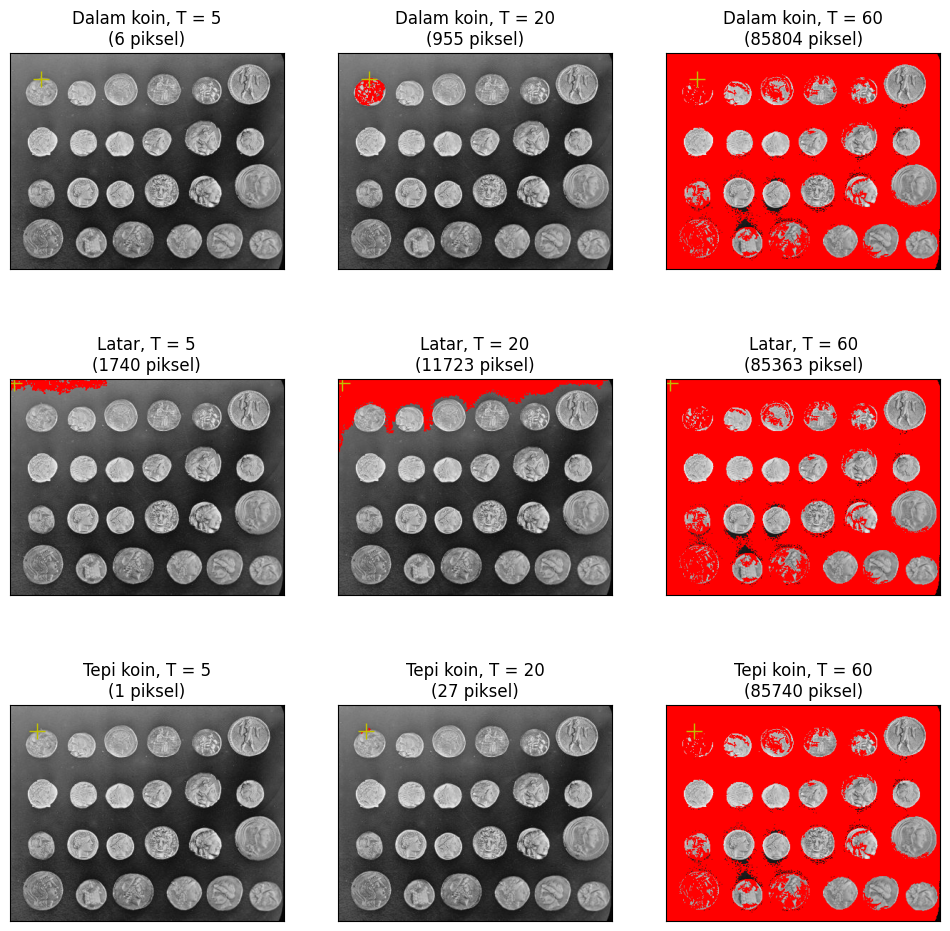

In [8]:
img = data.coins()      # grayscale, 303 x 384

def region_growing(img, seed, T):
    H, W = img.shape
    mask = np.zeros((H, W), dtype=bool)
    mask[seed] = True
    antrian = deque([seed])
    jumlah = 1
    total = float(img[seed])               # float agar tidak overflow uint8

    while antrian:
        r, c = antrian.popleft()
        for dr, dc in [(-1,0), (1,0), (0,-1), (0,1)]:       # 4 tetangga
            nr, nc = r + dr, c + dc
            if 0 <= nr < H and 0 <= nc < W and not mask[nr, nc]:
                if abs(float(img[nr, nc]) - total / jumlah) < T:
                    mask[nr, nc] = True
                    antrian.append((nr, nc))
                    total += float(img[nr, nc])
                    jumlah += 1
    return mask

# 3 seed (baris, kolom)
seeds = {'Dalam koin': (36, 43),
         'Latar':      (5, 5),
         'Tepi koin':  (36, 38)}
Ts = [5, 20, 60]

plt.figure(figsize=(12, 12))
n = 1
for nama, seed in seeds.items():
    print(nama, seed, "| intensitas:", img[seed])
    for T in Ts:
        mask = region_growing(img, seed, T)
        rgb = np.stack([img, img, img], axis=-1)
        rgb[mask] = [255, 0, 0]                              # region = merah
        plt.subplot(3, 3, n)
        plt.imshow(rgb)
        plt.plot(seed[1], seed[0], 'y+', markersize=12)      # tanda seed
        plt.title(f'{nama}, T = {T}\n({mask.sum()} piksel)')
        plt.xticks([]), plt.yticks([])
        n += 1
plt.show()

**B. Gunakan skimage.segmentation.flood(). Fungsi ini menghasilkan mask region dari
seed dengan menerima piksel yang terhubung dan intensitasnya berada dalam toleransi terhadap intensitas seed.**

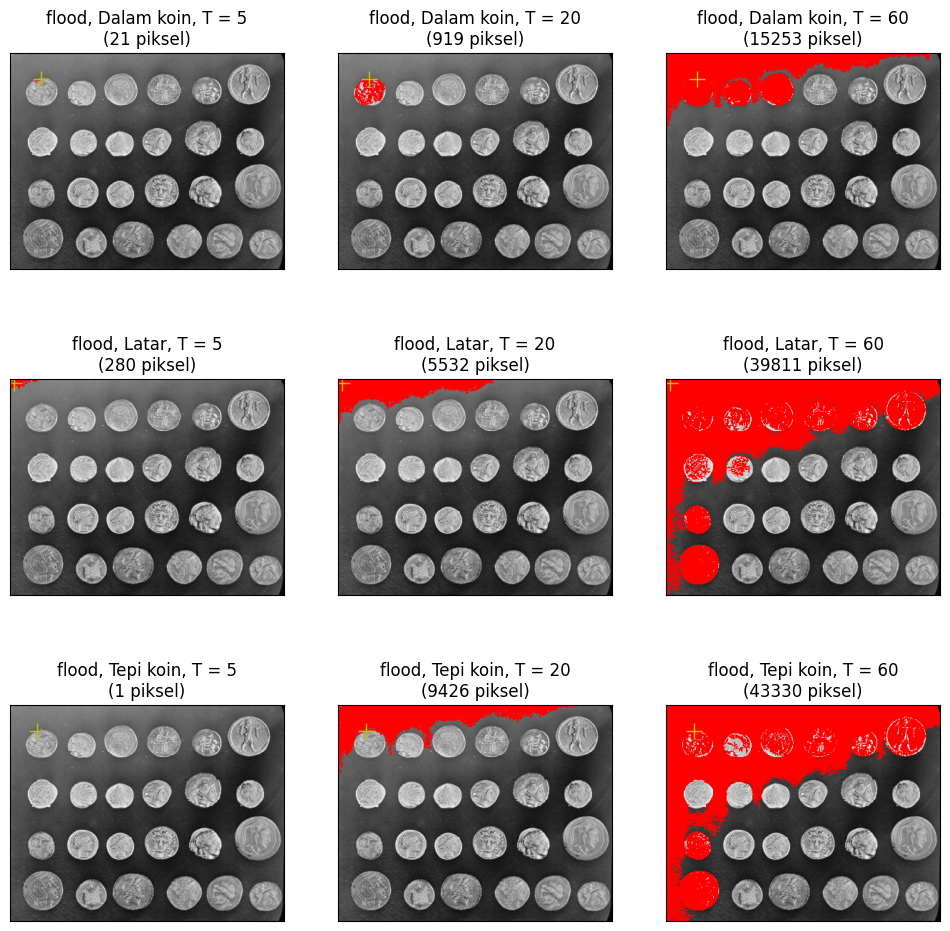

In [9]:
plt.figure(figsize=(12, 12))
n = 1
for nama, seed in seeds.items():
    for T in Ts:
        mask = flood(img, seed_point=seed, tolerance=T, connectivity=1)
        rgb = np.stack([img, img, img], axis=-1)
        rgb[mask] = [255, 0, 0]
        plt.subplot(3, 3, n)
        plt.imshow(rgb)
        plt.plot(seed[1], seed[0], 'y+', markersize=12)
        plt.title(f'flood, {nama}, T = {T}\n({mask.sum()} piksel)')
        plt.xticks([]), plt.yticks([])
        n += 1
plt.show()

**Penjelasan:**<br>
Region growing dijalankan dari tiga seed (dalam koin, latar, tepi koin) dengan T = 5, 20, dan 60. Pada T kecil region hanya berupa bercak, pada T = 20 seed dalam koin menutupi satu koin, dan pada T = 60 region bocor ke hampir seluruh citra (under-segmentation). Seed di tepi koin paling tidak stabil karena intensitasnya berada di peralihan latar dan koin. Hasil manual dan `flood` berbeda pada T besar karena manual membandingkan dengan rata-rata region yang berubah, sedangkan `flood` dengan nilai seed yang tetap.

7. **Lakukan segmentasi warna pada image ktp_fulan.jpg , munculkan hanya warna yang
biru saja. (Petunjuk: anda dapat gunakan K-Means untuk menampilkan hanya warna
tertentu saja).
Rentang mencakup biru muda kebiruan pada latar KTP (dengan warna HSV):
kelompok_biru = np.where( (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40) )**

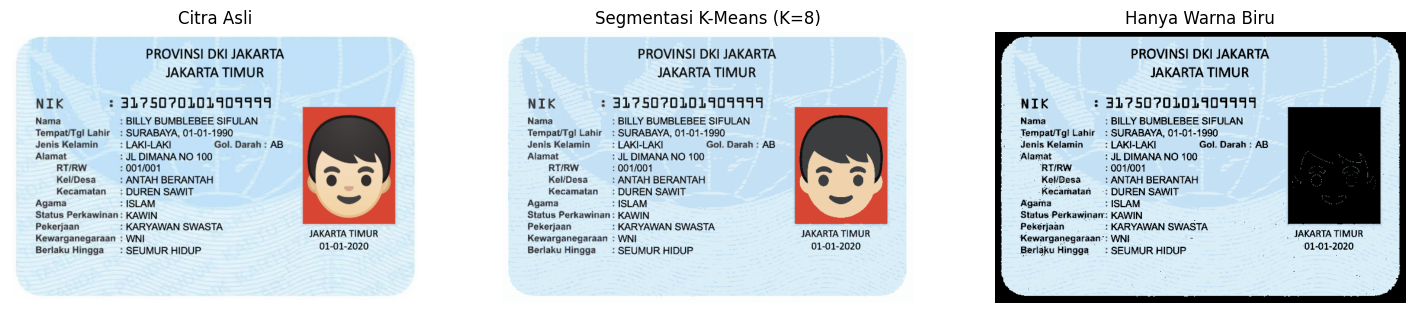

In [10]:
from sklearn.cluster import KMeans

# Baca citra dan ubah ke RGB
filename = ('/content/drive/MyDrive/PCVK2026/ktp_fulan.jpg')
img = cv.imread(filename)
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# Ubah citra menjadi array 2D (piksel)
Z = img.reshape((-1, 3))
Z = np.float32(Z)

# K-Means dengan K = 8
k = 8
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(Z)

labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

# Ubah hasil K-Means ke HSV, lalu ambil hanya warna biru
hsv = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
H, S, V = hsv[:,:,0], hsv[:,:,1], hsv[:,:,2]

kelompok_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

hanya_biru = np.zeros_like(segmented_img)       # semua hitam
hanya_biru[kelompok_biru] = segmented_img[kelompok_biru]   # warna biru dikembalikan

# Tampilkan
titles = ['Citra Asli', 'Segmentasi K-Means (K=8)', 'Hanya Warna Biru']
hasil = [img, segmented_img, hanya_biru]

plt.figure(figsize=(18,5))
for i in range(3):
    plt.subplot(1,3,i+1)
    plt.imshow(hasil[i])
    plt.title(titles[i])
    plt.axis('off')
plt.show()

**Penjelasan:**<br>
Segmentasi warna dilakukan dengan K-Means (K = 8) pada citra KTP sehingga warna citra disederhanakan menjadi 8 warna. Hasilnya diubah ke ruang warna HSV, lalu piksel yang memenuhi rentang biru (H 85-130, S ≥ 25, V ≥ 40) dipertahankan, sedangkan piksel lainnya dijadikan hitam. Pada hasilnya, latar KTP yang berwarna biru muda tetap tampil, sedangkan foto wajah yang berwarna merah-oranye menjadi hitam karena bukan warna biru. HSV dipakai karena memisahkan warna (Hue) dari kecerahan (Value), sehingga biru muda dan biru tua tetap terdeteksi.

<hr>

### **D2. Tugas Kelompok**<br>**Latihan: Lakukan Perbandingan Pembacaan Teks pada Citra Berwarna dan Hasil Segmentasi**

**Langkah 0: Install Tesseract**

In [11]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


**Langkah 1: Siapkan tiga citra untuk dibandingkan**

KTP HAFSYAH


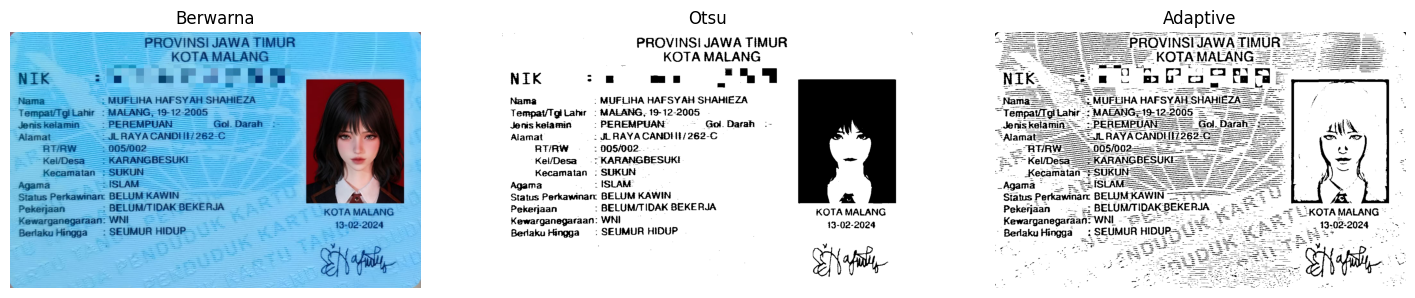

KTP ABID


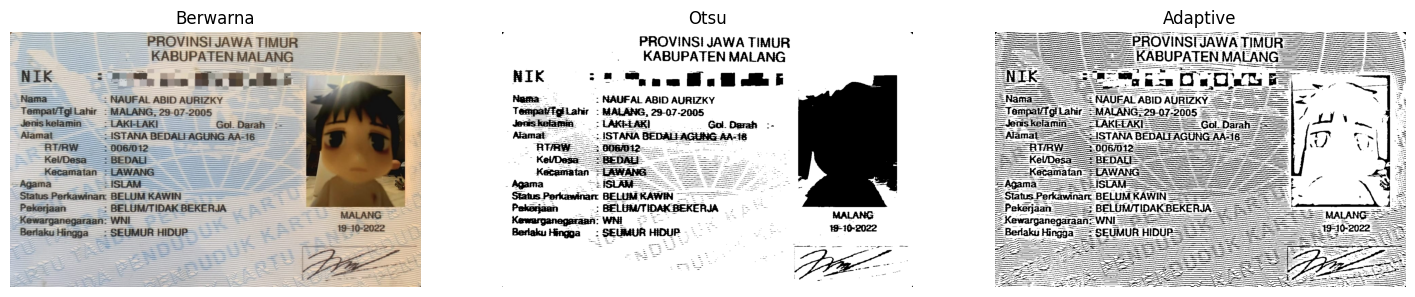

KTP FATTAH


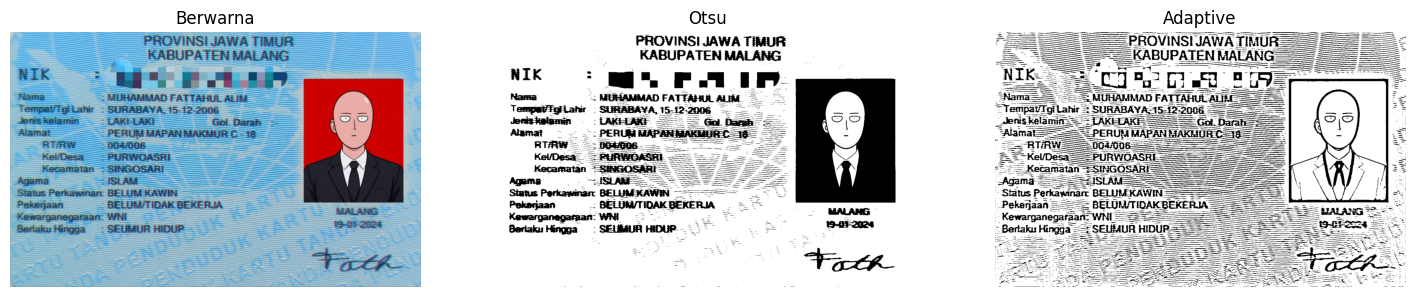

KTP FADHIL


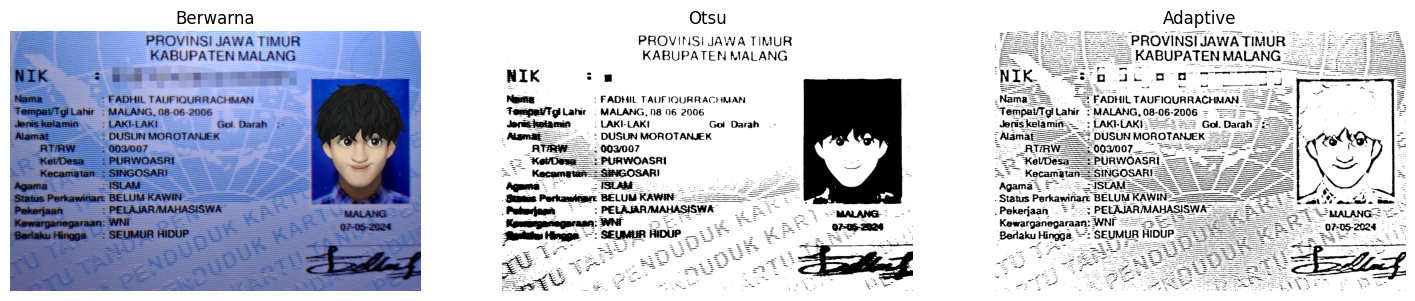

In [12]:
import pytesseract

folder = '/content/drive/MyDrive/PCVK2026/'
file_ktp = {'KTP HAFSYAH': 'ktp_hafsya.jpeg',
            'KTP ABID': 'ktp_abid.jpg',
            'KTP FATTAH': 'ktp_fattah.jpg',
            'KTP FADHIL': 'ktp_fadhil.jpg'}

semua_citra = {}
for anggota, nama_file in file_ktp.items():
    img = cv.imread(folder + nama_file)

    h, w = img.shape[:2]
    img = cv.resize(img, (1600, int(h * 1600 / w)), interpolation=cv.INTER_CUBIC)

    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    ret, img_otsu = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    img_adaptive = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 51, 15)
    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    semua_citra[anggota] = {'Berwarna': img_rgb, 'Otsu': img_otsu, 'Adaptive': img_adaptive}

    print(anggota)
    plt.figure(figsize=(18, 5))
    for i, (nama, citra) in enumerate(semua_citra[anggota].items()):
        plt.subplot(1, 3, i+1)
        plt.imshow(citra, cmap='gray' if citra.ndim == 2 else None)
        plt.title(nama)
        plt.axis('off')
    plt.show()

**Langkah 2: Lakukan pembacaan teks pada ketiga citra menggunakan pytesseract.image_to_string().**

In [13]:
config = '--psm 6'
hasil_teks = {}
for anggota, citra_ocr in semua_citra.items():
    hasil_teks[anggota] = {}
    print(f'\n######## {anggota} ########')
    for nama, citra in citra_ocr.items():
        hasil_teks[anggota][nama] = pytesseract.image_to_string(citra, lang='ind', config=config)
        print(f'========== {nama.upper()} ==========')
        print('\n'.join(l for l in hasil_teks[anggota][nama].splitlines() if l.strip()))
        print()


######## KTP HAFSYAH ########
========== BERWARNA ==========
"—-,—,——————m—wwbwbwbw— Www www w www ——-—:::--R
“Amuk FI. ——— 5.
an BN LI... .
Nama 2MUPLMA HAFSYAH SHAMIEZA )
“Tempat/Tgilahir : MAKANG,19-12-2005 — — — ———
- Pa ia Ro SN
Alamat —— jl RAYACANDHH 282 —-—— — — |
5 AAA .
— Maura MAMMEEESKI
Kecamatan FSUKUN 5 5 | |
A5 —
Status Perkawinan: BELUMKAWIN ————— —— MK
Pekerjaan » BELUM/TIDAK BEKERJA - ---—”—— —— OTAMALANG
Kewarganegaraan: WNI —— ————... 5. 55 5 g.pp-2024
Berlaku Hingga: SEUMUR HIDUP- -- ee” —— |
4 : 5 4

========== OTSU ==========
PROVINSI! JAWA TIMUR
KOTA MALANG
NIK : - al, 1
Nama : MUFLIHA HAFSYAH SHAHIEZA
Tempat/Tgi Lahir : MALANG, 19-12-2005 -
Jenis kelamin : PEREMPUAN - Gol. Darah :-
Alamat :JLRAYACANDHI/262-G
RAW - 1905/9002...
Kel/Desa 1 KARANGBESUKI .—
Kecamatan : SUKUN
Agama ISLAM"
Status Perkawinan BELUM KAWIN . PA
Pekerjaan : BELUM/TIDAK BEKERJA KOTA MALANG
Kewarganegaraan: WNI 13-02-2024
Beraku Flingga —: SEUMUR HIDUP
Sat,

========== ADAPTIVE ==========


**Langkah 3: Tampilkan area teks yang dikenali menggunakan pytesseract.image_to_data() dan kotak
hijau.**

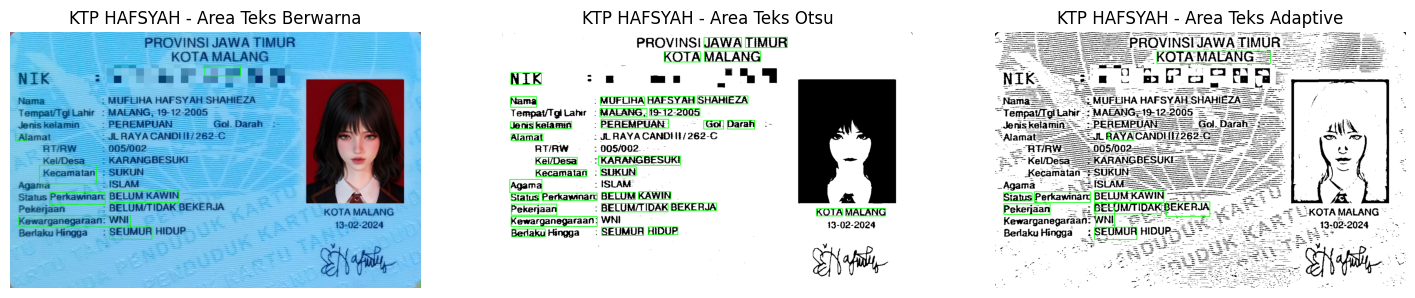

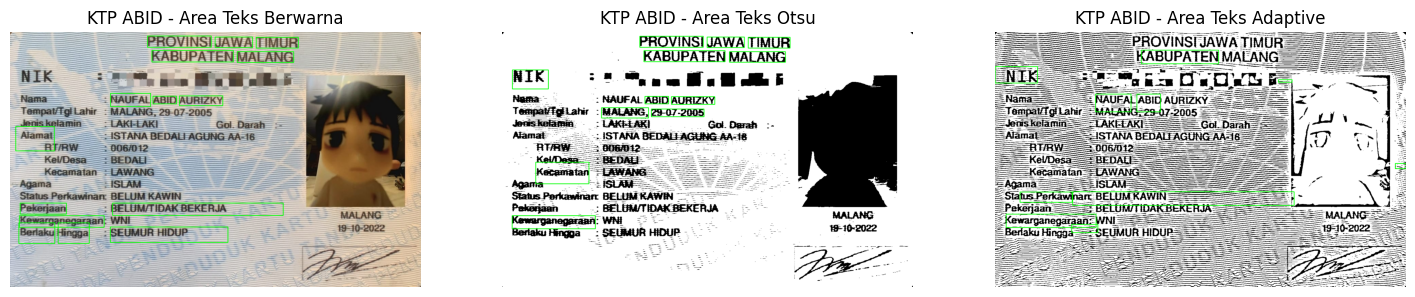

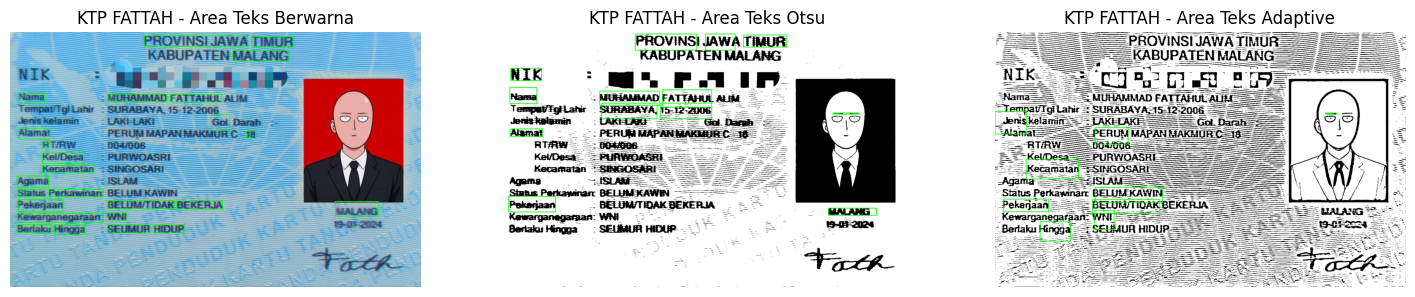

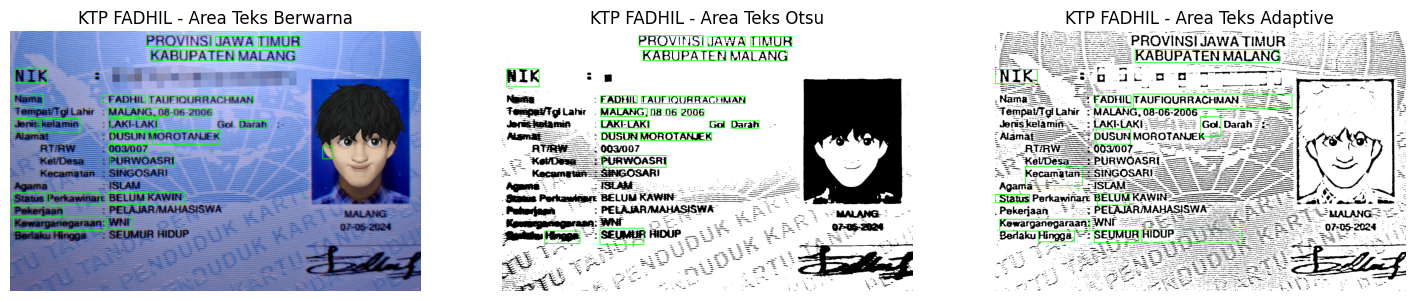

KTP HAFSYAH
   Berwarna   | conf rata-rata: 30.5 | kotak hijau: 8
   Otsu       | conf rata-rata: 71.2 | kotak hijau: 35
   Adaptive   | conf rata-rata: 30.0 | kotak hijau: 10
KTP ABID
   Berwarna   | conf rata-rata: 36.4 | kotak hijau: 15
   Otsu       | conf rata-rata: 54.1 | kotak hijau: 12
   Adaptive   | conf rata-rata: 26.7 | kotak hijau: 10
KTP FATTAH
   Berwarna   | conf rata-rata: 52.1 | kotak hijau: 26
   Otsu       | conf rata-rata: 49.5 | kotak hijau: 13
   Adaptive   | conf rata-rata: 22.8 | kotak hijau: 10
KTP FADHIL
   Berwarna   | conf rata-rata: 46.7 | kotak hijau: 28
   Otsu       | conf rata-rata: 35.1 | kotak hijau: 20
   Adaptive   | conf rata-rata: 29.9 | kotak hijau: 13


In [14]:
BATAS = 60
rata_conf = {}
jumlah_kotak = {}

for anggota, citra_ocr in semua_citra.items():
    rata_conf[anggota] = {}
    jumlah_kotak[anggota] = {}
    plt.figure(figsize=(18, 6))
    for i, (nama, citra) in enumerate(citra_ocr.items()):
        d = pytesseract.image_to_data(citra, lang='ind', config=config,
                                      output_type=pytesseract.Output.DICT)
        tampil = cv.cvtColor(citra, cv.COLOR_GRAY2RGB) if citra.ndim == 2 else citra.copy()

        daftar_conf = []
        n_kotak = 0
        for j in range(len(d['text'])):
            kata = d['text'][j].strip()
            conf = float(d['conf'][j])
            if kata == '' or conf < 0:
                continue
            daftar_conf.append(conf)                     # rata-rata dari semua kata terbaca
            if conf > BATAS and any(ch.isalnum() for ch in kata):
                x, y, w, h = d['left'][j], d['top'][j], d['width'][j], d['height'][j]
                cv.rectangle(tampil, (x, y), (x + w, y + h), (0, 255, 0), 2)
                n_kotak += 1

        rata_conf[anggota][nama] = np.mean(daftar_conf) if daftar_conf else 0
        jumlah_kotak[anggota][nama] = n_kotak

        plt.subplot(1, 3, i+1)
        plt.imshow(tampil)
        plt.title(f'{anggota} - Area Teks {nama}')
        plt.axis('off')
    plt.show()

for anggota in rata_conf:
    print(anggota)
    for nama in rata_conf[anggota]:
        print(f'   {nama:10s} | conf rata-rata: {rata_conf[anggota][nama]:.1f} | kotak hijau: {jumlah_kotak[anggota][nama]}')

**Langkah 4 dan 5: Tabel dan persentase kecocokan**

In [18]:
import pandas as pd
from IPython.display import display

acuan = {
    'KTP HAFSYAH': ['PROVINSI', 'JAWA TIMUR', 'KOTA MALANG', 'PEREMPUAN', 'ISLAM',
                   'BELUM KAWIN', 'BELUM/TIDAK BEKERJA', 'WNI', 'SEUMUR HIDUP', 'KARANGBESUKI'],
    'KTP ABID': ['PROVINSI', 'JAWA TIMUR', 'KABUPATEN MALANG', 'LAKI-LAKI', 'ISLAM',
                  'BELUM KAWIN', 'BELUM/TIDAK BEKERJA', 'WNI', 'SEUMUR HIDUP', 'BEDALI'],
    'KTP FATTAH': ['PROVINSI', 'JAWA TIMUR', 'KABUPATEN MALANG', 'LAKI-LAKI', 'ISLAM',
                  'BELUM KAWIN', 'BELUM/TIDAK BEKERJA', 'WNI', 'SEUMUR HIDUP', 'PURWOASRI'],
    'KTP FADHIL': ['PROVINSI', 'JAWA TIMUR', 'KABUPATEN MALANG', 'LAKI-LAKI', 'ISLAM',
                   'BELUM KAWIN', 'PELAJAR/MAHASISWA', 'WNI', 'SEUMUR HIDUP', 'PURWOASRI'],
}

# --- Hitung kecocokan tiap KTP dan tiap citra ---
baris = []
for anggota in semua_citra:
    for nama in semua_citra[anggota]:
        teks = ' '.join(hasil_teks[anggota][nama].split()).lower()
        tepat = [a for a in acuan[anggota] if a.lower().strip() in teks]
        gagal = [a for a in acuan[anggota] if a not in tepat]
        baris.append({
            'KTP': anggota,
            'Citra masukan OCR': nama,
            'Item terbaca tepat': f'{len(tepat)}/10',
            'Kecocokan (%)': len(tepat) * 10,
            'Rata-rata confidence': round(rata_conf[anggota][nama], 1),
            'Item tidak cocok': ', '.join(gagal) if gagal else '-',
            '_tepat': len(tepat),
        })

df = pd.DataFrame(baris)

# --- Tabel 1: per KTP ---
print('TABEL 1. Hasil per KTP')
tabel1 = df.drop(columns='_tepat').copy()
tabel1.loc[tabel1['KTP'].duplicated(), 'KTP'] = ''
display(tabel1.style.hide(axis='index').set_properties(**{'text-align': 'left'})
        .format({'Rata-rata confidence': '{:.1f}'}))

# --- Tabel 2: ringkasan gabungan ---
print('\nTABEL 2. Ringkasan gabungan semua KTP')
jml = df['KTP'].nunique() * 10
ringkas = df.groupby('Citra masukan OCR', sort=False).agg(
    tepat=('_tepat', 'sum'), conf=('Rata-rata confidence', 'mean')).reset_index()
tabel2 = pd.DataFrame({
    'Citra masukan OCR': ringkas['Citra masukan OCR'],
    'Item terbaca tepat': ringkas['tepat'].astype(str) + f'/{jml}',
    'Kecocokan (%)': (ringkas['tepat'] / jml * 100).round(1),
    'Rata-rata confidence': ringkas['conf'].round(1),
})
display(tabel2.style.hide(axis='index').set_properties(**{'text-align': 'left'})
        .format({'Kecocokan (%)': '{:.1f}', 'Rata-rata confidence': '{:.1f}'}))

TABEL 1. Hasil per KTP


KTP,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence,Item tidak cocok
KTP HAFSYAH,Berwarna,3/10,30,30.5,"PROVINSI, JAWA TIMUR, KOTA MALANG, PEREMPUAN, ISLAM, BELUM KAWIN, KARANGBESUKI"
,Otsu,10/10,100,71.2,-
,Adaptive,5/10,50,30.0,"JAWA TIMUR, KOTA MALANG, ISLAM, BELUM KAWIN, KARANGBESUKI"
KTP ABID,Berwarna,4/10,40,36.4,"PROVINSI, LAKI-LAKI, ISLAM, BELUM KAWIN, BELUM/TIDAK BEKERJA, BEDALI"
,Otsu,4/10,40,54.1,"LAKI-LAKI, ISLAM, BELUM KAWIN, BELUM/TIDAK BEKERJA, SEUMUR HIDUP, BEDALI"
,Adaptive,2/10,20,26.7,"JAWA TIMUR, LAKI-LAKI, ISLAM, BELUM KAWIN, BELUM/TIDAK BEKERJA, WNI, SEUMUR HIDUP, BEDALI"
KTP FATTAH,Berwarna,4/10,40,52.1,"JAWA TIMUR, LAKI-LAKI, ISLAM, BELUM KAWIN, SEUMUR HIDUP, PURWOASRI"
,Otsu,3/10,30,49.5,"KABUPATEN MALANG, LAKI-LAKI, ISLAM, BELUM KAWIN, WNI, SEUMUR HIDUP, PURWOASRI"
,Adaptive,4/10,40,22.8,"KABUPATEN MALANG, LAKI-LAKI, ISLAM, BELUM KAWIN, BELUM/TIDAK BEKERJA, PURWOASRI"
KTP FADHIL,Berwarna,8/10,80,46.7,"ISLAM, SEUMUR HIDUP"



TABEL 2. Ringkasan gabungan semua KTP


Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
Berwarna,19/40,47.5,41.4
Otsu,24/40,60.0,52.5
Adaptive,15/40,37.5,27.4


**Tabel 10 item**

In [17]:
from difflib import SequenceMatcher
import pandas as pd
import numpy as np
from IPython.display import display

def baca_item(item, teks_asli):
    """Return (teks yang terbaca, cocok?). Aturan cocok sama dengan Tabel 1."""
    teks_norm = ' '.join(teks_asli.split())
    if item.lower().strip() in teks_norm.lower():
        return item, True

    # Tidak cocok: cari potongan teks OCR yang paling mirip untuk ditampilkan
    tok = [t.strip(':;,.|_\'"`[]()') for t in teks_norm.split()]
    tok = [t for t in tok if t]
    n, target = len(item.split()), item.upper()
    terbaik, skor = '', 0.0
    for k in range(max(1, n - 1), n + 3):
        for i in range(len(tok) - k + 1):
            cand = ' '.join(tok[i:i + k]).upper()
            s = SequenceMatcher(None, cand, target).ratio()
            if s > skor:
                terbaik, skor = cand, s
    if skor >= 0.5:
        return terbaik, False
    return '(tidak terbaca)', False

kolom_ocr = [('Berwarna', 'OCR citra berwarna'),
             ('Otsu', 'OCR Otsu'),
             ('Adaptive', 'OCR Adaptive')]

for anggota in semua_citra:
    baris, status = [], []
    for no, item in enumerate(acuan[anggota], start=1):
        row = {'No.': no, 'Teks sebenarnya': item}
        ok_row = [True, True]
        for nama, kolom in kolom_ocr:
            baca, ok = baca_item(item, hasil_teks[anggota][nama])
            row[kolom] = baca
            ok_row.append(ok)
        baris.append(row)
        status.append(ok_row)

    df = pd.DataFrame(baris)
    css = pd.DataFrame(np.where(np.array(status), '', 'background-color: #f8d7da'),
                       index=df.index, columns=df.columns)

    print(f'\nTABEL 10 ITEM - {anggota}')
    display(df.style.apply(lambda _: css, axis=None)
              .hide(axis='index')
              .set_properties(**{'text-align': 'left'}))


TABEL 10 ITEM - KTP HAFSYAH


No.,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
1,PROVINSI,(tidak terbaca),PROVINSI,PROVINSI
2,JAWA TIMUR,AAA — MAURA,JAWA TIMUR,PROVINSIJAWATIMURE—-
3,KOTA MALANG,OTAMALANG,KOTA MALANG,KOTAMALANG
4,PEREMPUAN,PEKERJAAN,PEREMPUAN,PEREMPUAN
5,ISLAM,IA,ISLAM,SISAMS
6,BELUM KAWIN,BELUMKAWIN,BELUM KAWIN,BELUMKAWIN
7,BELUM/TIDAK BEKERJA,BELUM/TIDAK BEKERJA,BELUM/TIDAK BEKERJA,BELUM/TIDAK BEKERJA
8,WNI,WNI,WNI,WNI
9,SEUMUR HIDUP,SEUMUR HIDUP,SEUMUR HIDUP,SEUMUR HIDUP
10,KARANGBESUKI,PERKAWINAN BELUMKAWIN,KARANGBESUKI,“KARANGBESUKE



TABEL 10 ITEM - KTP ABID


No.,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
1,PROVINSI,ROVINSI,PROVINSI,PROVINSI
2,JAWA TIMUR,JAWA TIMUR,JAWA TIMUR,PROVINSIJAWA TMORE
3,KABUPATEN MALANG,KABUPATEN MALANG,KABUPATEN MALANG,KABUPATEN MALANG
4,LAKI-LAKI,(tidak terbaca),(tidak terbaca),-ANKAI
5,ISLAM,ISTANA,LA,LA
6,BELUM KAWIN,(tidak terbaca),(tidak terbaca),BELUMKAWIN
7,BELUM/TIDAK BEKERJA,BELUM/TIDAKBEKERJA,(tidak terbaca),BELUMTIDAKBEKERJA
8,WNI,WNI,WNI,NIK
9,SEUMUR HIDUP,SEUMUR HIDUP,(tidak terbaca),(tidak terbaca)
10,BEDALI,BEDALAGUNG,(tidak terbaca),TE AI



TABEL 10 ITEM - KTP FATTAH


No.,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
1,PROVINSI,PROVINSI,PROVINSI,PROVINSI
2,JAWA TIMUR,PROVINSIJAWA HMUR,JAWA TIMUR,JAWA TIMUR
3,KABUPATEN MALANG,KABUPATEN MALANG,KABUPATENMALANG,KABUPATENMALANG
4,LAKI-LAKI,LAKETAKI,(tidak terbaca),LAKEAKE
5,ISLAM,SSEAM,5S ALAMAT,ISIAM
6,BELUM KAWIN,BELUMKAWIN,BELUM/TIDAK,BELUMKAWIN
7,BELUM/TIDAK BEKERJA,BELUM/TIDAK BEKERJA,BELUM/TIDAK BEKERJA,BELUMTIDAK BEKERJA
8,WNI,WNI,(tidak terbaca),WNI
9,SEUMUR HIDUP,SEHMUR HIDUP,SELMUR HIDUP,SEUMUR HIDUP
10,PURWOASRI,PIR YGASRI,(tidak terbaca),OASRI



TABEL 10 ITEM - KTP FADHIL


No.,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
1,PROVINSI,PROVINSI,PROVINSI,(tidak terbaca)
2,JAWA TIMUR,JAWA TIMUR,JAWA TIMUR,ALAMAR
3,KABUPATEN MALANG,KABUPATEN MALANG,KABUPATEN MALANG,KABUPATENMALANG
4,LAKI-LAKI,LAKI-LAKI,LAKI-LAKI,LAKI-LAKI
5,ISLAM,JENIS KELAMIN,ISTAMS,ISIAM
6,BELUM KAWIN,BELUM KAWIN,JERMSKATAMIN,BELUM KAWIN
7,PELAJAR/MAHASISWA,PELAJAR/MAHASISWA,PELAJARMAHASISWA,(tidak terbaca)
8,WNI,WNI,WNI,WNI
9,SEUMUR HIDUP,(tidak terbaca),SEUMUR HIDUP,SEUMUR HIDUP
10,PURWOASRI,PURWOASRI,PURWOASRI,EPURWOASRL


### **Pertanyaan analisis:**
#### **1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.**<br>Jawaban:

In [21]:
metode = [nama for nama, _ in kolom_ocr]   # ['Berwarna', 'Otsu', 'Adaptive']
baris, total_benar, total_item = [], {m: 0 for m in metode}, 0

for anggota in semua_citra:
    n_item = len(acuan[anggota])
    benar = {m: sum(baca_item(item, hasil_teks[anggota][m])[1] for item in acuan[anggota])
             for m in metode}
    for m in metode:
        total_benar[m] += benar[m]
    total_item += n_item

    terbaik = [m for m in metode if benar[m] == max(benar.values())]
    baris.append({'Anggota': anggota,
                  **{f'{m} (benar)': benar[m] for m in metode},
                  **{f'{m} (%)': benar[m] / n_item * 100 for m in metode},
                  'Terbaik': ' / '.join(terbaik)})

# Baris gabungan semua anggota
gab = {'Anggota': 'GABUNGAN',
       **{f'{m} (benar)': total_benar[m] for m in metode},
       **{f'{m} (%)': total_benar[m] / total_item * 100 for m in metode}}
gab['Terbaik'] = ' / '.join(m for m in metode if total_benar[m] == max(total_benar.values()))
baris.append(gab)

df_no1 = pd.DataFrame(baris)
fmt = {f'{m} (%)': '{:.1f}' for m in metode}
display(df_no1.style.hide(axis='index').format(fmt))

# Kalimat ringkas untuk dikutip di jawaban
best = max(total_benar, key=total_benar.get)
print(f'\nMetode terbaik (gabungan): {best} '
      f'= {total_benar[best]}/{total_item} item = {total_benar[best] / total_item * 100:.1f}%')
for m in metode:
    print(f'{m}: {total_benar[m]}/{total_item} = {total_benar[m] / total_item * 100:.1f}%')

Anggota,Berwarna (benar),Otsu (benar),Adaptive (benar),Berwarna (%),Otsu (%),Adaptive (%),Terbaik
KTP HAFSYAH,3,10,5,30.0,100.0,50.0,Otsu
KTP ABID,4,4,2,40.0,40.0,20.0,Berwarna / Otsu
KTP FATTAH,4,3,4,40.0,30.0,40.0,Berwarna / Adaptive
KTP FADHIL,8,7,4,80.0,70.0,40.0,Berwarna
GABUNGAN,19,24,15,47.5,60.0,37.5,Otsu



Metode terbaik (gabungan): Otsu = 24/40 item = 60.0%
Berwarna: 19/40 = 47.5%
Otsu: 24/40 = 60.0%
Adaptive: 15/40 = 37.5%


**Penjelasan:**<br>
Citra masukan yang menghasilkan pembacaan paling tepat secara keseluruhan adalah citra hasil segmentasi Otsu, dengan 24 dari 40 item terbaca tepat (kecocokan 60,0%). Citra berwarna asli berada di urutan kedua dengan 19/40 (47,5%), dan segmentasi Adaptive paling rendah dengan 15/40 (37,5%).<br>
Namun, keunggulan Otsu tidak merata pada semua KTP. Otsu unggul jelas hanya pada KTP Hafsyah (10/10 atau 100%, dibanding 3/10 pada citra berwarna dan 5/10 pada Adaptive). Pada KTP Abid, Otsu dan citra berwarna seri (4/10). Pada KTP Fattah dan Fadhil, citra berwarna justru lebih baik dari Otsu (Fattah 4/10 vs 3/10, Fadhil 8/10 vs 7/10).

<hr>

#### **2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca.**<br>Jawaban:

In [22]:
def jenis_salah(item, terbaca):
    if terbaca == '(tidak terbaca)':
        return 'Tidak terbaca'
    ada_angka = any(c.isdigit() for c in item)
    return 'Angka salah' if ada_angka else 'Huruf salah/tertukar'

metode = [nama for nama, _ in kolom_ocr]
salah = []
for anggota in semua_citra:
    for no, item in enumerate(acuan[anggota], start=1):
        for m in metode:
            baca, ok = baca_item(item, hasil_teks[anggota][m])
            if not ok:
                salah.append({'Anggota': anggota, 'No.': no, 'Metode': m,
                              'Teks sebenarnya': item, 'Terbaca OCR': baca,
                              'Jenis': jenis_salah(item, baca)})

df_salah = pd.DataFrame(salah)

# 1) Ringkasan jumlah kesalahan per metode dan jenis
print('RINGKASAN JUMLAH KESALAHAN')
display(pd.crosstab(df_salah['Metode'], df_salah['Jenis'], margins=True))

# 2) Kandidat contoh terbaik: terbaca tapi salah (ada bukti apa yang dibaca)
kandidat = df_salah[df_salah['Jenis'] != 'Tidak terbaca']
print('\nKANDIDAT CONTOH (terbaca tapi salah)')
display(kandidat.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

# 3) Item yang tidak terbaca
print('\nITEM TIDAK TERBACA')
display(df_salah[df_salah['Jenis'] == 'Tidak terbaca']
        .style.hide(axis='index').set_properties(**{'text-align': 'left'}))

RINGKASAN JUMLAH KESALAHAN


Jenis,Huruf salah/tertukar,Tidak terbaca,All
Metode,,,
Adaptive,22,3,25
Berwarna,17,4,21
Otsu,8,8,16
All,47,15,62



KANDIDAT CONTOH (terbaca tapi salah)


Anggota,No.,Metode,Teks sebenarnya,Terbaca OCR,Jenis
KTP HAFSYAH,2,Berwarna,JAWA TIMUR,AAA — MAURA,Huruf salah/tertukar
KTP HAFSYAH,2,Adaptive,JAWA TIMUR,PROVINSIJAWATIMURE—-,Huruf salah/tertukar
KTP HAFSYAH,3,Berwarna,KOTA MALANG,OTAMALANG,Huruf salah/tertukar
KTP HAFSYAH,3,Adaptive,KOTA MALANG,KOTAMALANG,Huruf salah/tertukar
KTP HAFSYAH,4,Berwarna,PEREMPUAN,PEKERJAAN,Huruf salah/tertukar
KTP HAFSYAH,5,Berwarna,ISLAM,IA,Huruf salah/tertukar
KTP HAFSYAH,5,Adaptive,ISLAM,SISAMS,Huruf salah/tertukar
KTP HAFSYAH,6,Berwarna,BELUM KAWIN,BELUMKAWIN,Huruf salah/tertukar
KTP HAFSYAH,6,Adaptive,BELUM KAWIN,BELUMKAWIN,Huruf salah/tertukar
KTP HAFSYAH,10,Berwarna,KARANGBESUKI,PERKAWINAN BELUMKAWIN,Huruf salah/tertukar



ITEM TIDAK TERBACA


Anggota,No.,Metode,Teks sebenarnya,Terbaca OCR,Jenis
KTP HAFSYAH,1,Berwarna,PROVINSI,(tidak terbaca),Tidak terbaca
KTP ABID,4,Berwarna,LAKI-LAKI,(tidak terbaca),Tidak terbaca
KTP ABID,4,Otsu,LAKI-LAKI,(tidak terbaca),Tidak terbaca
KTP ABID,6,Berwarna,BELUM KAWIN,(tidak terbaca),Tidak terbaca
KTP ABID,6,Otsu,BELUM KAWIN,(tidak terbaca),Tidak terbaca
KTP ABID,7,Otsu,BELUM/TIDAK BEKERJA,(tidak terbaca),Tidak terbaca
KTP ABID,9,Otsu,SEUMUR HIDUP,(tidak terbaca),Tidak terbaca
KTP ABID,9,Adaptive,SEUMUR HIDUP,(tidak terbaca),Tidak terbaca
KTP ABID,10,Otsu,BEDALI,(tidak terbaca),Tidak terbaca
KTP FATTAH,4,Otsu,LAKI-LAKI,(tidak terbaca),Tidak terbaca


**Penjelasan:**<br>
Beberapa kesalahan pembacaan yang ditemukan diantaranya yaitu:
* Huruf salah: contohnya pada KTP Fattah, “SEUMUR HIDUP” terbaca “SEHMUR HIDUP” pada citra berwarna dan “SELMUR HIDUP” pada Otsu (huruf U terbaca H dan L).
* Huruf salah/tambahan: contohnya pada KTP Fadhil, “PURWOASRI” terbaca “EPURWOASRL” pada Adaptive (ada huruf E tambahan di depan dan huruf I terbaca L).
* Teks tidak terbaca: contohnya pada KTP Abid, “LAKI-LAKI” tidak terbaca sama sekali pada citra berwarna maupun Otsu. Pada KTP Hafsyah, “PROVINSI” tidak terbaca pada citra berwarna.
* Spasi antarkata hilang: contohnya “BELUM KAWIN” terbaca “BELUMKAWIN” (KTP Hafsyah, citra berwarna dan Adaptive) dan “KABUPATEN MALANG” terbaca “KABUPATENMALANG” (KTP Fattah, Otsu dan Adaptive). Hurufnya benar, tetapi dihitung tidak cocok karena spasi di tengah kata hilang.

Secara keseluruhan terdapat 62 pembacaan salah dari 120 pembacaan yaitu Adaptive 25, citra berwarna 21, dan Otsu 16. Pada Otsu, 8 dari 16 kesalahan berupa teks yang tidak terbaca sama sekali, sedangkan pada Adaptive kesalahan didominasi huruf yang terbaca keliru (22 dari 25).

<hr>

#### **3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.**<br>Jawaban:
Tidak, segmentasi tidak selalu meningkatkan ketepatan OCR. Hasilnya bergantung pada KTP dan metode yang dipakai.
* Otsu meningkatkan kecocokan secara gabungan (47,5% menjadi 60,0%), tetapi peningkatan itu hampir seluruhnya berasal dari KTP Hafsyah (30% menjadi 100%). Pada KTP Abid hasilnya sama (40%), sedangkan pada KTP Fattah (40% menjadi 30%) dan Fadhil (80% menjadi 70%) kecocokan justru turun. Jika KTP Hafsyah dikeluarkan, kecocokan Otsu (46,7%) lebih rendah daripada citra berwarna (53,3%).
* Adaptive tidak meningkatkan kecocokan secara gabungan (47,5% menjadi 37,5%). Metode ini hanya membantu pada KTP Hafsyah (30% menjadi 50%), sama pada Fattah (40%), dan menurunkan hasil pada Abid (40% menjadi 20%) dan Fadhil (80% menjadi 40%).
* Segmentasi juga mengubah jenis kesalahan. Pada Otsu, pembacaan yang salah turun dari 17 menjadi 8, tetapi teks yang sama sekali tidak terbaca naik dari 4 menjadi 8, misalnya “LAKI-LAKI” dan “BELUM KAWIN” pada KTP Abid dan “PURWOASRI” pada KTP Fattah. Pada Adaptive, pembacaan yang salah justru naik dari 17 menjadi 22. Artinya thresholding dapat menghilangkan teks yang sebenarnya terbaca pada citra berwarna, atau menambah noise yang mengganggu pembacaan.

Jadi segmentasi paling bermanfaat bila citra aslinya sulit dibaca (seperti KTP Hafsyah yang hanya 30% pada citra berwarna), dan kurang bermanfaat atau merugikan bila citra berwarna sudah terbaca cukup baik (KTP Fadhil 80%).

<hr>

#### **4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?**<br>Jawaban:
* Warna dan pola latar belakang sangat memengaruhi pembacaan teks. Pada citra berwarna, latar KTP berupa biru muda dengan pola globe dan gradasi warna, sehingga kontras antara teks dan latar tidak seragam dan pola latar ikut terbaca sebagai karakter. Hal ini terlihat pada area header: pada citra berwarna, “JAWA TIMUR” terbaca “AAA — MAURA” (KTP Hafsyah), dan 4 dari 8 pembacaan header salah atau tidak terbaca.
* Otsu mengubah latar menjadi putih polos sehingga pola latar hilang. Akibatnya, seluruh 8 pembacaan header (“PROVINSI” dan “JAWA TIMUR” pada 4 KTP) terbaca tepat pada Otsu. Sebaliknya, Adaptive Thresholding bekerja dengan ambang lokal, sehingga pola dan gradasi halus pada latar ikut menjadi bintik atau garis noise. Hal ini terlihat dari “JAWA TIMUR” yang terbaca “PROVINSIJAWATIMURE—–”, yaitu dua baris header tergabung dengan karakter sampah, dan 4 dari 8 pembacaan header salah.
* Pengaruh latar tidak sepenuhnya menjelaskan semua kesalahan. Kata pendek seperti “ISLAM” salah pada 11 dari 12 pembacaan di semua metode, dan kemungkinan penyebabnya adalah ukuran tulisan yang kecil dan kata yang pendek sehingga OCR kekurangan konteks. Selain itu Otsu juga menghasilkan 8 teks tidak terbaca, yang menunjukkan bahwa thresholding global yang menghilangkan latar dapat ikut menghilangkan teks pada area tertentu.

<hr>

#### **5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?**<br> Jawaban:
Iya, pada data gabungan keempat KTP, metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi. Otsu memiliki rata-rata confidence tertinggi (52,5) dan kecocokan tertinggi (60,0% atau 24 dari 40 item). Urutan berikutnya sama pada kedua ukuran: citra berwarna (confidence 41,4 dan kecocokan 47,5%) dan Adaptive (confidence 27,4 dan kecocokan 37,5%).<br><br>
Namun, keduanya mengukur hal yang berbeda. Confidence adalah tingkat keyakinan mesin OCR terhadap hasil bacaannya sendiri, sedangkan kecocokan dihitung dengan membandingkan hasil dengan teks sebenarnya. Confidence yang tinggi tidak menjamin hasilnya benar, dan kesesuaian urutan di sini berasal dari data gabungan. Pada tingkat per KTP, hubungan keduanya belum tentu sama. Misalnya pada KTP Fattah, citra berwarna dan Adaptive sama-sama 40%, sehingga confidence tidak bisa dipakai membedakannya. Karena itu confidence cocok sebagai indikator kasar kualitas pembacaan, tetapi tidak dapat menggantikan pemeriksaan terhadap teks sebenarnya.